# 3. Verification: ground snow depth and held-out satellite maps

Two independent checks of the Reynolds Creek product:

1. **Ground snow depth** at the USDA-ARS Northwest Watershed Research Center network (daily, 40 sites, water years 2000-2026): melt-out dates and day-by-day snow presence.
2. **Held-out Landsat and Sentinel-2 maps**: how well the downscaling reproduces the 30 m pattern when the persistence ranking is built from other years.

Production scripts: `validate_rcew_ground.py`, `fig_rcew_ground_validation.py`, `ds_eval.py`.

The snow depth record was provided by Andrew Hedrick (USDA-ARS) and is read here from `../../ground/rcew_ars/`. It is not part of the snow-cover data release unless ARS agrees to include it.

*Disclosure: the processing code and these notebooks were written with the assistance of Claude (Anthropic), working under the direction of the authors.*

In [1]:
import os, sys, io, tarfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4

ROOT = Path("..")                      # essd_draft/
CODE = ROOT / "code"
DATA = Path("data"); DATA.mkdir(exist_ok=True)
os.environ["SNOW_DOMAIN"] = "rcew"     # the pipeline code reads the domain from this variable
sys.path.insert(0, str(CODE))

SEASONS_NC = ROOT / "rcew_snow_seasons_30m_v1.nc"
DAILY_STEM = "rcew_snowcover_daily_30m_v1"   # one file, or parts along time (see daily_io.py)
MODIS_TAR = ROOT / "inputs" / "rcew_mod10a1f_window_2000_2026.tar"
EXAMPLE_DATE = pd.Timestamp("2019-03-18")   # clear Landsat 8 overpass with a partly snow-covered watershed

plt.rcParams.update({"font.size": 9, "figure.dpi": 110, "axes.facecolor": "#d4d4d4"})   # grey = outside or no data
from matplotlib.colors import LinearSegmentedColormap
SNOW = LinearSegmentedColormap.from_list("snow", ["#5c4326", "#9c7a4e", "#cdbb98", "#e6e9ea", "#ffffff"])   # bare ground to snow

In [2]:
S = netCDF4.Dataset(SEASONS_NC)
grab = lambda k: np.ma.filled(S[k][:].astype(float), np.nan)
x, y = S["x"][:], S["y"][:]
region = np.ma.filled(S["region"][:], 0).astype(int)
inside = region > 0
elev, slope, aspect = grab("elevation"), grab("slope"), grab("aspect")
forest = np.ma.filled(S["forest"][:], 0).astype(bool)
persistence = grab("snow_persistence")
extent = [x.min() - 15, x.max() + 15, y.min() - 15, y.max() + 15]
NY, NX = region.shape
print(f"grid {NY} x {NX} cells at 30 m, {inside.sum() * 900 / 1e6:.0f} km2 inside the watershed, "
      f"{np.nanmin(elev):.0f}-{np.nanmax(elev):.0f} m, forest share {forest[inside].mean():.0%}")

grid 1030 x 560 cells at 30 m, 240 km2 inside the watershed, 1104-2241 m, forest share 15%


## 3.1 The ground network

Snow is counted as present on the ground when depth exceeds 5 cm. Rows flagged `qc_suspect_zero` (a one-day drop from 20 cm or more straight to zero, which looks like a processing break) are left out.

40 sites with data, 391,979 site-days, 1999-11-24 to 2026-09-30


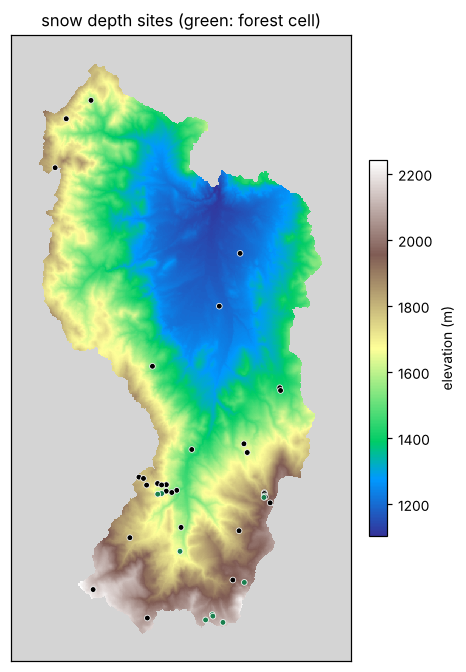

In [3]:
from pyproj import Transformer

GROUND = ROOT / ".." / "ground" / "rcew_ars"
depth = pd.read_csv(GROUND / "rcew_ars_snowdepth_daily_tidy.csv", parse_dates=["date"])
depth = depth[depth.qc_suspect_zero == 0]
sites = pd.read_csv(GROUND / "rcew_ars_snowdepth_sites.csv").set_index("site")
sites["x"], sites["y"] = Transformer.from_crs(4326, 32611, always_xy=True).transform(sites.longitude.values, sites.latitude.values)
sites["ix"] = [int(np.argmin(abs(x - v))) for v in sites.x]; sites["iy"] = [int(np.argmin(abs(y - v))) for v in sites.y]
sites["forest_cell"] = forest[sites.iy, sites.ix]
print(f"{depth.site.nunique()} sites with data, {len(depth):,} site-days, {depth.date.min().date()} to {depth.date.max().date()}")

fig, ax = plt.subplots(figsize=(4.2, 6), constrained_layout=True)
im = ax.imshow(elev, extent=extent, cmap="terrain", interpolation="nearest")
ax.scatter(sites.x, sites.y, s=14, c=np.where(sites.forest_cell, "#1a7f4e", "k"), edgecolor="w", lw=0.5)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("snow depth sites (green: forest cell)"); fig.colorbar(im, ax=ax, shrink=0.6, label="elevation (m)")
plt.show()

## 3.2 One site, one winter

Depth at a high-elevation site against the product's daily snow cover at the 30 m cell that contains it, with the main season found by the same rules in both records.

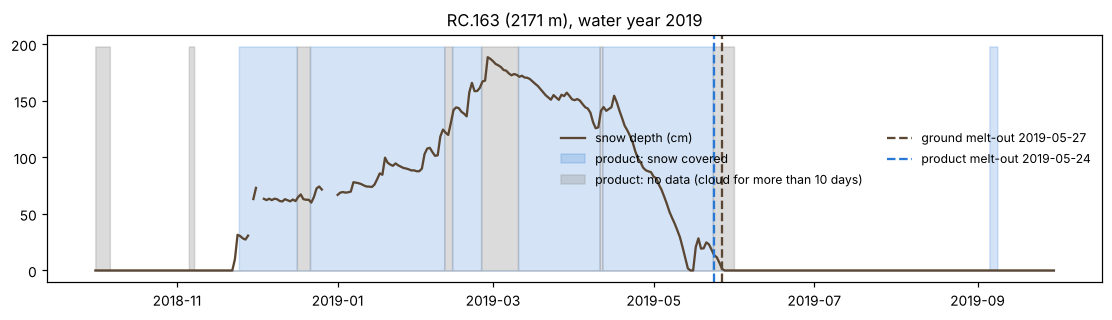

In [4]:
from ondates import season

from daily_io import Daily

D = Daily(ROOT, DAILY_STEM)


def site_series(site, wy):
    """Daily ground snow (depth > 5 cm) and product snow cover at the site's cell for one water year."""
    days = pd.date_range(f"{wy - 1}-10-01", f"{wy}-09-30")
    g = depth[depth.site == site].set_index("date").depth_cm.reindex(days)
    sc = D.cell("snow_cover", sites.iy[site], sites.ix[site], days[0], days[-1]).reindex(days)
    return days, g, sc


SITE, WY = "RC.163", 2019
days, g, sc = site_series(SITE, WY)
sg = season(np.where(g.isna(), np.nan, (g > 5).astype(float))); ss = season(sc.values)
fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True); ax.set_facecolor("white")
ax.plot(days, g, color="#5a4632", label="snow depth (cm)")
ax.fill_between(days, 0, np.where(sc == 1, g.max() * 1.05, 0), step="mid", color="#2a78d6", alpha=0.2, label="product: snow covered")
ax.fill_between(days, 0, np.where(sc.isna(), g.max() * 1.05, 0), step="mid", color="#999999", alpha=0.35, label="product: no data (cloud for more than 10 days)")
ax.axvline(days[int(sg["snow_off"])], color="#5a4632", ls="--", label=f"ground melt-out {days[int(sg['snow_off'])].date()}")
ax.axvline(days[int(ss["snow_off"])], color="#2a78d6", ls="--", label=f"product melt-out {days[int(ss['snow_off'])].date()}")
ax.set_title(f"{SITE} ({sites.elevation_m[SITE]} m), water year {WY}"); ax.legend(frameon=False, fontsize=8, ncol=2)
plt.show()

## 3.3 Melt-out dates at all sites and years

`validate_rcew_ground.py` repeats that comparison for every site and water year using the seasons file. A site-year is used when at least 80% of its November-May days have a depth record and both records have a main season that does not run into the start or end of the water year.

In shallow, intermittent snowpacks a mid-winter melt can split the winter into two runs of similar length, and the ground and satellite records may then pick different runs as the "main season". The comparison is therefore shown separately for site-years with **one clear season** in both records (no more than 14 snow days outside the main season) and for **split** seasons.

In [5]:
import subprocess

VAL = DATA / "validation"
uploads = ROOT / ".." / ".." / "uploads" / "hearth"
raw_depth, raw_meta = uploads / "8e1479ae-0a70-4296-930e-d1502ee197f7", uploads / "2eb797c9-804b-4c1c-93dd-f125d85f9f06"
if raw_depth.exists():       # rerun the production script on the files as received
    subprocess.run([sys.executable, str(CODE / "validate_rcew_ground.py"), str(raw_depth), str(raw_meta), str(SEASONS_NC),
                    str(CODE), str(VAL)], check=True, capture_output=True)
    pairs = pd.read_csv(VAL / "rcew_ground_vs_30m_by_site_wy.csv")
else:                        # otherwise read the released table
    pairs = pd.read_csv(ROOT / "validation" / "rcew_ground_vs_30m_by_site_wy.csv")

ok = pairs[(pairs.cov_nov_may >= 0.8) & (pairs.censored == 0)].dropna(subset=["ground_off", "sat_off"]).copy()
ok["single"] = ((ok.ground_scd - (ok.ground_off - ok.ground_on)) <= 14) & ((ok.sat_scd - (ok.sat_off - ok.sat_on)) <= 14)
ok["err"] = ok.sat_off - ok.ground_off


def summary(d):
    return pd.Series({"site-years": len(d), "bias, median (d)": d.err.median(), "MAE (d)": d.err.abs().mean(),
                      "r": np.corrcoef(d.ground_off, d.sat_off)[0, 1]})


table = pd.DataFrame({"all": summary(ok), "one clear season": summary(ok[ok.single]),
                      "one clear season, open cells": summary(ok[ok.single & (ok.forest == 0)]),
                      "one clear season, forest cells": summary(ok[ok.single & (ok.forest == 1)]),
                      "split season": summary(ok[~ok.single])}).T
table.round(2)

,site-years,"bias, median (d)",MAE (d),r
all,595.0,-1.0,18.30,0.76
one clear season,296.0,0.0,11.31,0.89
"one clear season, open cells",201.0,3.0,10.52,0.92
"one clear season, forest cells",95.0,-9.0,12.99,0.81
split season,299.0,-1.0,25.22,0.59


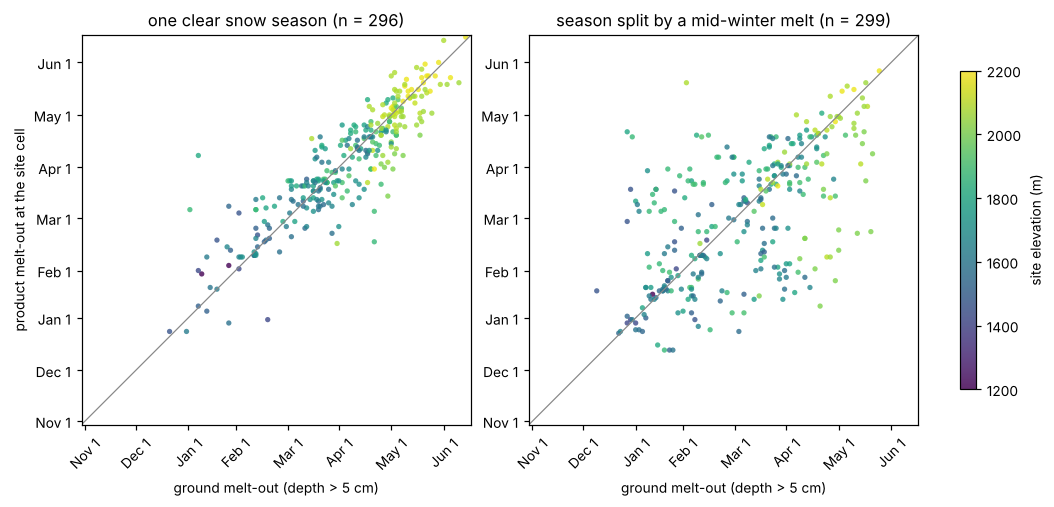

In [6]:
ticks = [32, 62, 93, 121, 152, 182, 213, 244]; labels = ["Nov 1", "Dec 1", "Jan 1", "Feb 1", "Mar 1", "Apr 1", "May 1", "Jun 1"]
fig, axs = plt.subplots(1, 2, figsize=(9.5, 4.6), constrained_layout=True)
for ax, single, title in [(axs[0], True, "one clear snow season"), (axs[1], False, "season split by a mid-winter melt")]:
    d = ok[ok.single == single]
    sc_ = ax.scatter(d.ground_off, d.sat_off, c=d.elev_site, cmap="viridis", s=12, alpha=0.8, lw=0, vmin=1200, vmax=2200)
    ax.plot([30, 260], [30, 260], color="#888888", lw=0.8); ax.set_facecolor("white")
    ax.set_xlim(30, 260); ax.set_ylim(30, 260); ax.set_aspect("equal"); ax.set_title(f"{title} (n = {len(d)})")
    ax.set_xticks(ticks, labels, rotation=45); ax.set_yticks(ticks, labels); ax.set_xlabel("ground melt-out (depth > 5 cm)")
axs[0].set_ylabel("product melt-out at the site cell"); fig.colorbar(sc_, ax=axs, shrink=0.7, label="site elevation (m)")
plt.show()

## 3.4 Day-by-day agreement

A second check does not depend on the season definition: on each November-May day, does the product show snow where the ground has more than 5 cm? The full table for all sites is in `../validation/rcew_ground_daily_agreement.csv`. Reading 27 years of daily values at every site takes several minutes, so the cell below computes the score live for four sites across the elevation range and then loads the released table.

In [7]:
def daily_pairs(site):
    """All Nov-May days with both a depth record and a product value at one site."""
    g = depth[depth.site == site].set_index("date").depth_cm
    sc = D.cell("snow_cover", sites.iy[site], sites.ix[site], g.index.min(), g.index.max())
    j = pd.concat([g.rename("depth"), sc.rename("sat")], axis=1, join="inner").dropna()
    j = j[j.index.month.isin([11, 12, 1, 2, 3, 4, 5])]
    return pd.DataFrame({"ground": j.depth > 5, "sat": j.sat == 1})


def scores(j):
    tp = (j.ground & j.sat).sum(); fp = (~j.ground & j.sat).sum(); fn = (j.ground & ~j.sat).sum(); tn = (~j.ground & ~j.sat).sum()
    return {"days": len(j), "accuracy": (tp + tn) / len(j), "precision": tp / (tp + fp), "recall": tp / (tp + fn),
            "F": 2 * tp / (2 * tp + fp + fn), "ground snow share": j.ground.mean(), "product snow share": j.sat.mean()}


example_sites = ["RC.095b", "RC.snotel", "RC.167b", "RC.163"]
live = pd.DataFrame({f"{s} ({sites.elevation_m[s]} m)": scores(daily_pairs(s)) for s in example_sites}).T
live.round(2)

,days,accuracy,precision,recall,F,ground snow share,product snow share
RC.095b (1534 m),4566.0,0.85,0.50,0.77,0.60,0.15,0.24
RC.snotel (1705 m),4895.0,0.89,0.87,0.87,0.87,0.40,0.40
RC.167b (1936 m),3997.0,0.91,0.95,0.89,0.92,0.62,0.58
RC.163 (2171 m),5124.0,0.94,0.98,0.96,0.97,0.86,0.84


In [8]:
pd.read_csv(ROOT / "validation" / "rcew_ground_daily_agreement.csv").set_index("subset")

,n,acc,precision,recall,F,ground_snow,sat_snow
subset,,,,,,,
all Nov-May,213186,0.794,0.612,0.850,0.711,0.30,0.42
open,160001,0.813,0.573,0.879,0.694,0.24,0.37
forest,53185,0.737,0.690,0.805,0.743,0.47,0.55
"< 1,600 m",53524,0.848,0.519,0.836,0.641,0.16,0.26
"1,600-1,900 m",106523,0.780,0.541,0.852,0.662,0.25,0.40
">= 1,900 m",53139,0.767,0.745,0.852,0.795,0.53,0.61
observed that day (not gap-filled),79199,0.853,0.652,0.879,0.748,0.25,0.33
gap-filled,133987,0.759,0.595,0.836,0.695,0.33,0.46
partial-snow input,73184,0.613,0.553,0.857,0.672,0.46,0.72


The product rarely misses snow that the sensors record (recall), but it shows snow on more days than the 5 cm depth rule does (precision). Agreement is highest on days when MODIS saw the pixel and when its snow fraction was near 0 or 1, and lowest on gap-filled days and where the persistence ranking had to place a partial snow fraction. Those cases are identified by the `quality` flags in the daily file.

## 3.5 Held-out satellite maps (split-year cross-validation)

The 30 m pattern is checked against Landsat and Sentinel-2 snow maps with the F-measure of notebook 2, on cells in partly snow-covered MODIS pixels. To keep the test independent, the persistence ranking is built from odd water years when scoring scenes from even years, and the reverse (`ds_eval.py`). Rows compare the persistence ranking (`emp_smooth`) with the terrain score (`smooth`), fed either the true snow fraction from the 30 m map itself (`ideal`) or the MODIS fraction (`modis`); `F_random` is a random order.

In [9]:
cv = pd.read_csv(ROOT / "validation" / "rcew_downscale_crossval_split_years.csv")
cv["ranking"] = cv.kind.map({"emp_smooth": "snow persistence", "smooth": "terrain score"})
cv[["input", "ranking", "F", "F_open", "F_forest", "F_random", "n_scenes"]].set_index(["input", "ranking"])

F  F_open  F_forest  F_random  n_scenes
input ranking                                                      
ideal snow persistence  0.780   0.784     0.746     0.640       340
      terrain score     0.716   0.681     0.753     0.640       340
modis snow persistence  0.727   0.730     0.718     0.648       292
      terrain score     0.694   0.661     0.728     0.648       292

## Summary

| check | result at Reynolds Creek |
|---|---|
| Melt-out against ground depth, all site-years | median bias near zero, mean absolute error about 18 days |
| Melt-out, one clear season in both records | mean absolute error about 11 days, r about 0.9 |
| Forest cells | melt-out about 9 days early |
| Daily snow presence, November-May | about 79% agreement; 85% on days MODIS saw the pixel |
| 30 m pattern against held-out Landsat and Sentinel-2 | F 0.73 with the persistence ranking, 0.69 with the terrain score, 0.65 random |

The tables printed above are the source for these numbers.